# LAB 3 – Bài 2 (Trang 5): Neural Network phân lớp MNIST (train – validation – test)

In [1]:
HO_TEN = "Trang Kim Đạt"
MSSV = "6451071018"
print(f"{HO_TEN} – {MSSV}")

Trang Kim Đạt – 6451071018


In [ ]:
print(f"{HO_TEN} – {MSSV}")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

Trang Kim Đạt – 6451071018


c:\Users\trang\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [3]:
print(f"{HO_TEN} – {MSSV}")
def danh_gia(ten_mo_hinh, y_true, y_pred, target_names=None):
    """In Accuracy, Precision/Recall/F1 (từng lớp + trung bình) và vẽ confusion matrix dạng heatmap."""
    print(f"===== {ten_mo_hinh} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=target_names if target_names is not None else "auto",
                yticklabels=target_names if target_names is not None else "auto")
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion matrix - {ten_mo_hinh}")
    plt.show()

Trang Kim Đạt – 6451071018


## Câu a) Đọc bộ dữ liệu MNIST từ Keras

In [4]:
print(f"{HO_TEN} – {MSSV}")
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

Trang Kim Đạt – 6451071018


## Câu b) Kích thước tập train, test

In [5]:
print(f"{HO_TEN} – {MSSV}")
print("train_images:", train_images.shape, "| train_labels:", train_labels.shape)
print("test_images :", test_images.shape, "| test_labels :", test_labels.shape)

Trang Kim Đạt – 6451071018
train_images: (60000, 28, 28) | train_labels: (60000,)
test_images : (10000, 28, 28) | test_labels : (10000,)


## Câu c) Chuẩn hóa giá trị pixel về [0, 1]

In [6]:
print(f"{HO_TEN} – {MSSV}")
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Giá trị nhỏ nhất / lớn nhất:", train_images.min(), train_images.max())

Trang Kim Đạt – 6451071018
Giá trị nhỏ nhất / lớn nhất: 0.0 1.0


## Câu d) Chia tập train thành train và validation theo tỷ lệ 8:2

In [7]:
print(f"{HO_TEN} – {MSSV}")
train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42)
print("train     :", train_images.shape, train_labels.shape)
print("validation:", validation_images.shape, validation_labels.shape)

Trang Kim Đạt – 6451071018
train     : (48000, 28, 28) (48000,)
validation: (12000, 28, 28) (12000,)


## Câu e) Xây dựng Neural Network
Flatten → Dense(128, ReLU) → Dropout(0.2) → Dense(10, Softmax)

In [8]:
print(f"{HO_TEN} – {MSSV}")
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax"),
])
model.summary()

Trang Kim Đạt – 6451071018


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Câu f) Biên dịch mô hình

In [9]:
print(f"{HO_TEN} – {MSSV}")
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

Trang Kim Đạt – 6451071018


## Câu g) Huấn luyện (epoch = 5, batch_size = 32), đánh giá với tập validation

In [10]:
print(f"{HO_TEN} – {MSSV}")
history = model.fit(train_images, train_labels,
                    validation_data=(validation_images, validation_labels),
                    epochs=5, batch_size=32, verbose=1)

Trang Kim Đạt – 6451071018
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9050 - loss: 0.3287 - val_accuracy: 0.9537 - val_loss: 0.1658
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9531 - loss: 0.1612 - val_accuracy: 0.9638 - val_loss: 0.1221
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9647 - loss: 0.1204 - val_accuracy: 0.9704 - val_loss: 0.1033
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9706 - loss: 0.0969 - val_accuracy: 0.9733 - val_loss: 0.0923
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9745 - loss: 0.0817 - val_accuracy: 0.9732 - val_loss: 0.0899


## Câu h) Biểu đồ accuracy, loss sau mỗi epoch

Trang Kim Đạt – 6451071018


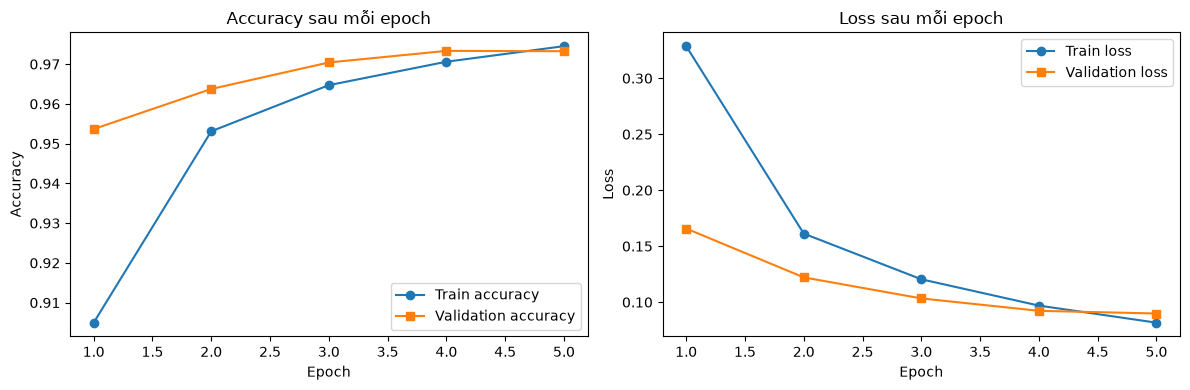

In [11]:
print(f"{HO_TEN} – {MSSV}")
epochs = range(1, len(history.history["accuracy"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, history.history["accuracy"], "o-", label="Train accuracy")
ax[0].plot(epochs, history.history["val_accuracy"], "s-", label="Validation accuracy")
ax[0].set_title("Accuracy sau mỗi epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend()
ax[1].plot(epochs, history.history["loss"], "o-", label="Train loss")
ax[1].plot(epochs, history.history["val_loss"], "s-", label="Validation loss")
ax[1].set_title("Loss sau mỗi epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()
plt.tight_layout(); plt.show()

## Câu i) Dự đoán phân lớp cho tập test

In [12]:
print(f"{HO_TEN} – {MSSV}")
y_prob = model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)
print("Kích thước ma trận xác suất:", y_prob.shape)
print("10 nhãn dự đoán đầu tiên:", y_pred[:10])
print("10 nhãn thực tế đầu tiên:", test_labels[:10])

Trang Kim Đạt – 6451071018
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Kích thước ma trận xác suất: (10000, 10)
10 nhãn dự đoán đầu tiên: [7 2 1 0 4 1 4 9 5 9]
10 nhãn thực tế đầu tiên: [7 2 1 0 4 1 4 9 5 9]


## Câu j, k, l) Accuracy, Precision/Recall/F1-score và Confusion matrix trên tập test

Trang Kim Đạt – 6451071018
===== Neural Network - MNIST =====
Accuracy: 0.9745
              precision    recall  f1-score   support

           0     0.9877    0.9867    0.9872       980
           1     0.9850    0.9868    0.9859      1135
           2     0.9610    0.9777    0.9693      1032
           3     0.9620    0.9762    0.9690      1010
           4     0.9688    0.9796    0.9742       982
           5     0.9741    0.9709    0.9725       892
           6     0.9761    0.9802    0.9781       958
           7     0.9765    0.9708    0.9737      1028
           8     0.9719    0.9579    0.9648       974
           9     0.9817    0.9564    0.9689      1009

    accuracy                         0.9745     10000
   macro avg     0.9745    0.9743    0.9744     10000
weighted avg     0.9746    0.9745    0.9745     10000



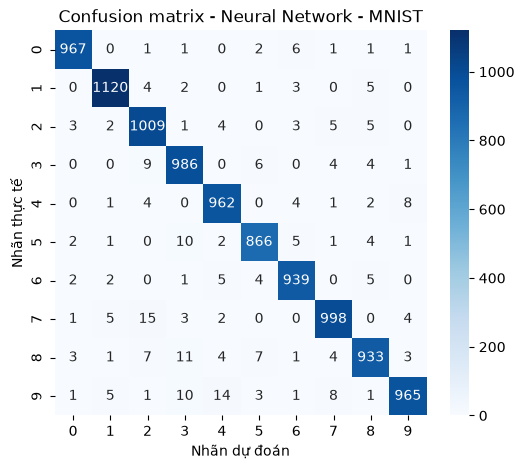

In [13]:
print(f"{HO_TEN} – {MSSV}")
danh_gia("Neural Network - MNIST", test_labels, y_pred, [str(i) for i in range(10)])

## Câu m) Kết quả phân lớp của 05 ảnh đầu tiên trong tập test

Trang Kim Đạt – 6451071018
Ảnh 0: nhãn thực tế = 7, dự đoán = 7
Ảnh 1: nhãn thực tế = 2, dự đoán = 2
Ảnh 2: nhãn thực tế = 1, dự đoán = 1
Ảnh 3: nhãn thực tế = 0, dự đoán = 0
Ảnh 4: nhãn thực tế = 4, dự đoán = 4


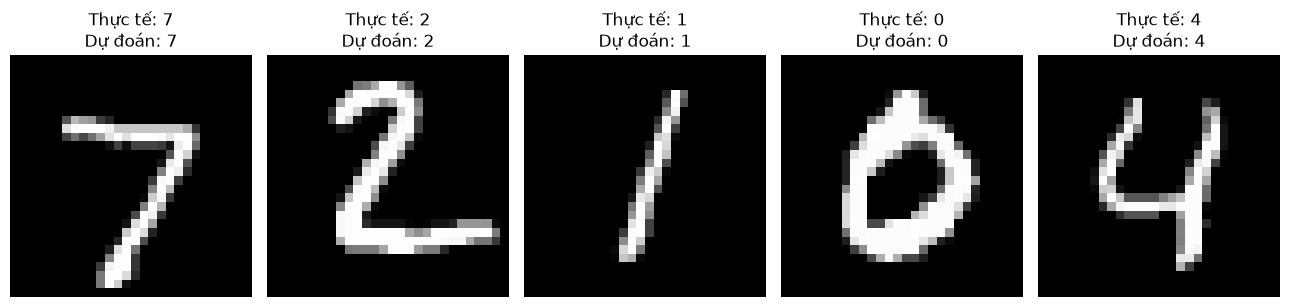

In [14]:
print(f"{HO_TEN} – {MSSV}")
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for image_index in range(5):
    anh = np.expand_dims(test_images[image_index], axis=0)
    du_doan = np.argmax(model.predict(anh, verbose=0), axis=1)[0]
    axes[image_index].imshow(test_images[image_index], cmap="gray")
    axes[image_index].set_title(f"Thực tế: {test_labels[image_index]}\nDự đoán: {du_doan}")
    axes[image_index].axis("off")
    print(f"Ảnh {image_index}: nhãn thực tế = {test_labels[image_index]}, dự đoán = {du_doan}")
plt.tight_layout(); plt.show()

## Câu n) 05 kết quả đầu tiên phân lớp sai so với nhãn thực tế

Trang Kim Đạt – 6451071018
Chỉ số 5 ảnh đầu tiên bị phân lớp sai: [151 247 321 340 359]
Ảnh #151: thực tế = 9, dự đoán = 8
Ảnh #247: thực tế = 4, dự đoán = 2
Ảnh #321: thực tế = 2, dự đoán = 7
Ảnh #340: thực tế = 5, dự đoán = 3
Ảnh #359: thực tế = 9, dự đoán = 4


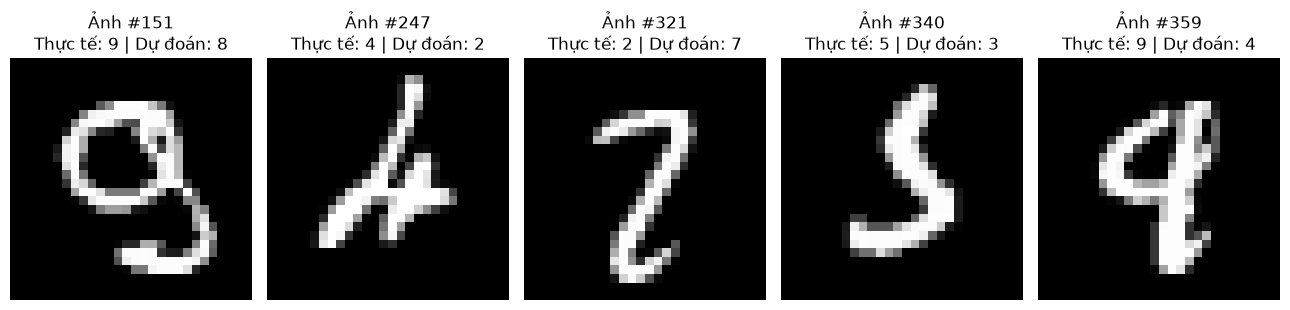

In [15]:
print(f"{HO_TEN} – {MSSV}")
chi_so_sai = np.where(y_pred != test_labels)[0][:5]
print("Chỉ số 5 ảnh đầu tiên bị phân lớp sai:", chi_so_sai)
fig, axes = plt.subplots(1, len(chi_so_sai), figsize=(13, 3))
for ax, idx in zip(np.atleast_1d(axes), chi_so_sai):
    ax.imshow(test_images[idx], cmap="gray")
    ax.set_title(f"Ảnh #{idx}\nThực tế: {test_labels[idx]} | Dự đoán: {y_pred[idx]}")
    ax.axis("off")
    print(f"Ảnh #{idx}: thực tế = {test_labels[idx]}, dự đoán = {y_pred[idx]}")
plt.tight_layout(); plt.show()